# Getting started with psp.clobe

*The vignette `vignette("clobe")` of the R package clobe, ported to `psp.clobe`.*

clobe compares the *range of behaviour* a computational model can produce with the range of behaviour people actually show. Instead of asking "how close is the model to the average participant?", it asks two questions:

1. Can the model produce what each participant did? (**accommodation**)
2. Does the model also produce many things nobody did? (**excess flexibility**)

g-distance (Dome & Wills, 2025) combines the two into a single number. This notebook walks through the whole workflow on simulated data, and then does the same with a parameter space partitioning run in place of a grid. The other notebooks explain each step and its mathematics in more detail:

- [inequality-matrices.ipynb](inequality-matrices.ipynb): how a result becomes an ordinal pattern.
- [universal-set.ipynb](universal-set.ipynb): counting every pattern that could occur.
- [gdistance.ipynb](gdistance.ipynb): accommodation, excess flexibility and g-distance.

In [1]:
import sys

import matplotlib
import numpy as np
import pandas as pd
import torch
from IPython.display import Markdown, display
import matplotlib.pyplot as plt

from psp import clobe

sys.path.insert(0, "..")  # for notebooks/figure_style.py
from figure_style import aqua, blue, figures, ink, light, muted, orange, reference, titled

show = figures("clobe-getting-started")

torch.set_printoptions(precision=2)


def rows(matrices):
    """Each pattern as a tuple of the cells above the diagonal."""
    k = matrices.shape[-1]
    i, j = torch.triu_indices(k, k, offset=1)
    return [tuple(row.tolist()) for row in matrices[:, i, j]]


def keys(matrices):
    return set(rows(matrices))


## The experiment

Imagine an experiment with four conditions (we will call them *stimuli*). Each of 40 participants does 20 trials per stimulus, and we record the proportion of trials on which they gave a particular response. Participants differ: some respond more often as we go from stimulus 1 to stimulus 4, some less often, and some barely change.

The data are simulated as in the R vignette, with torch's random number generator, so the numbers differ from the R version.

In [2]:
g = torch.Generator().manual_seed(2025)
x = torch.tensor([-1.5, -0.5, 0.5, 1.5], dtype=torch.float64)  # a feature of each stimulus
slopes = 0.5 + torch.randn(40, generator=g, dtype=torch.float64)
p = torch.sigmoid(slopes[:, None] * x + 0.3 * torch.randn(40, 4, generator=g, dtype=torch.float64))
human = torch.binomial(torch.full_like(p, 20.0), p, generator=g) / 20
human[:6]

tensor([[0.30, 0.25, 0.65, 0.65],
        [0.65, 0.80, 0.20, 0.35],
        [0.55, 0.65, 0.40, 0.50],
        [0.55, 0.30, 0.70, 0.40],
        [0.30, 0.50, 0.45, 0.55],
        [0.10, 0.30, 0.75, 0.85]], dtype=torch.float64)

Each participant has their own slope, drawn around 0.5, plus a little noise for each stimulus, and each proportion comes from 20 trials. Drawn one line per participant, the differences between people are plain; the average (black) is a single smooth curve that hides them.

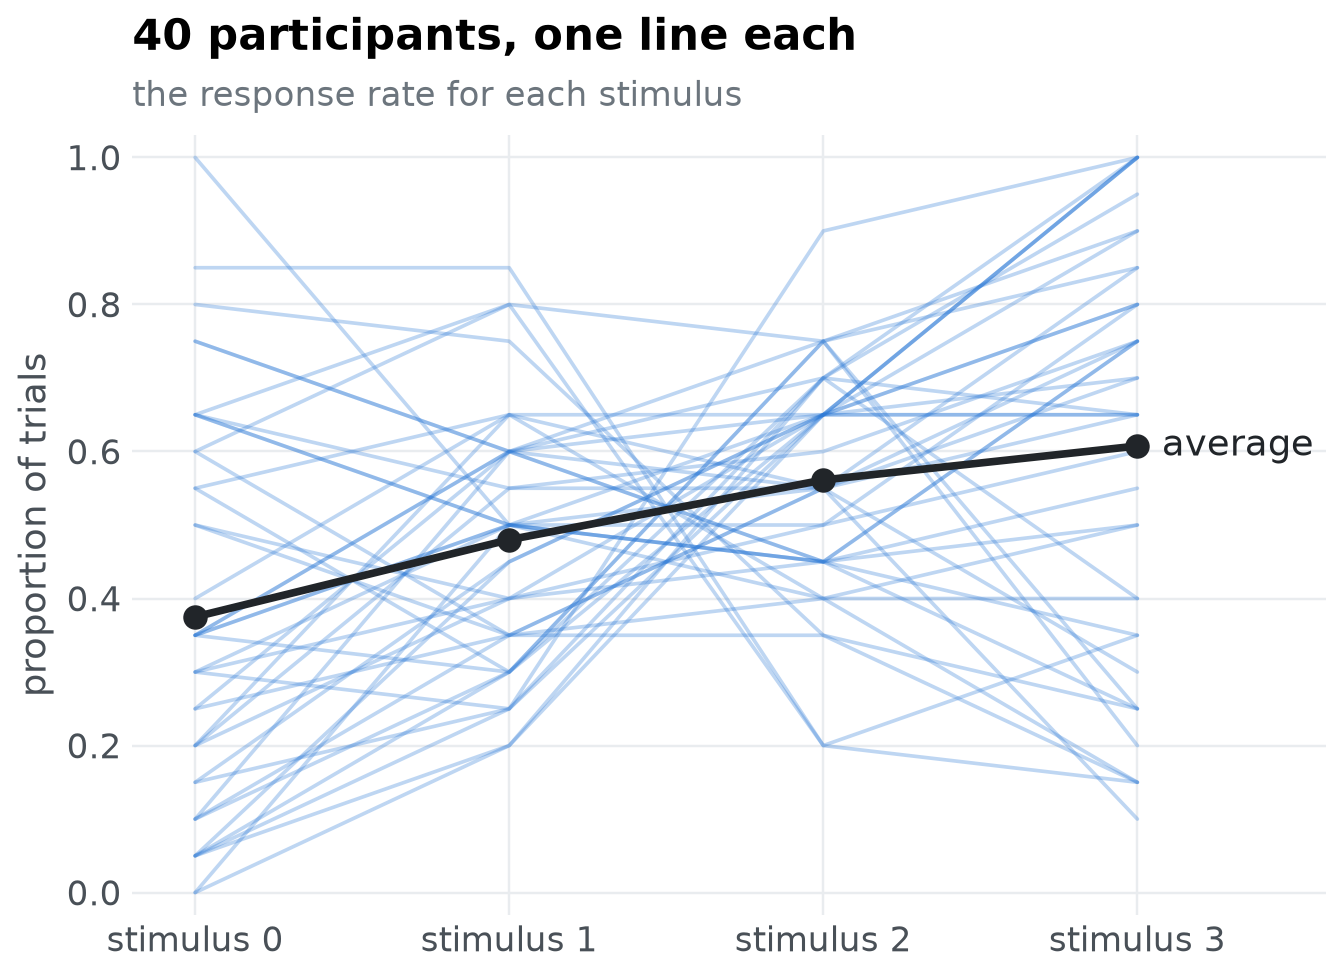

In [3]:
fig, ax = plt.subplots(figsize=(7, 4.6))
stimuli = np.arange(4)
for row in human:
    ax.plot(stimuli, row, color=blue, alpha=0.3, linewidth=1.2)
ax.plot(stimuli, human.mean(0), color=ink, linewidth=2.5, marker="o", markersize=7)
ax.annotate("average", (3, float(human.mean(0)[3])), xytext=(8, 0), textcoords="offset points",
            color=ink, va="center")
ax.set(xticks=stimuli, xticklabels=[f"stimulus {s}" for s in stimuli], ylim=(-0.03, 1.03),
       xlim=(-0.2, 3.6), ylabel="proportion of trials")
titled(ax, "40 participants, one line each", "the response rate for each stimulus")
show(fig, "participants")

## Step 1: turn each result into a pattern

Averaging these rows would hide the differences between participants. Instead, we describe each participant by the *ordinal pattern* of their results: for every pair of stimuli, is the first larger, smaller, or about the same as the second? "About the same" means the difference is no larger than a threshold, here 0.1 (two trials out of twenty).

In [4]:
thresholds = (0.1, -0.1)
clobe.imac(human[0], thresholds)

tensor([[ 2.,  0., -1., -1.],
        [ 2.,  2., -1., -1.],
        [ 2.,  2.,  2.,  0.],
        [ 2.,  2.,  2.,  2.]], dtype=torch.float64)

Read the matrix row against column: the entry in row 0 and column 2 says how stimulus 0 compares with stimulus 2 (1 larger, -1 smaller, 0 about the same; indices start at 0, as everywhere in Python). Only the cells above the diagonal carry information; the others are set to 2.

`patterns()` does this for every participant and keeps each distinct pattern once, with how often it occurred:

In [5]:
people = clobe.patterns(human, thresholds)
people.n, people.counts

(22,
 tensor([3, 1, 1, 1, 4, 1, 2, 1, 2, 1, 9, 3, 1, 1, 1, 1, 1, 2, 1, 1, 1, 1]))

In [6]:
display(Markdown(f"The {people.n} distinct patterns among 40 participants are the behaviour the model should be able to produce."))

The 22 distinct patterns among 40 participants are the behaviour the model should be able to produce.

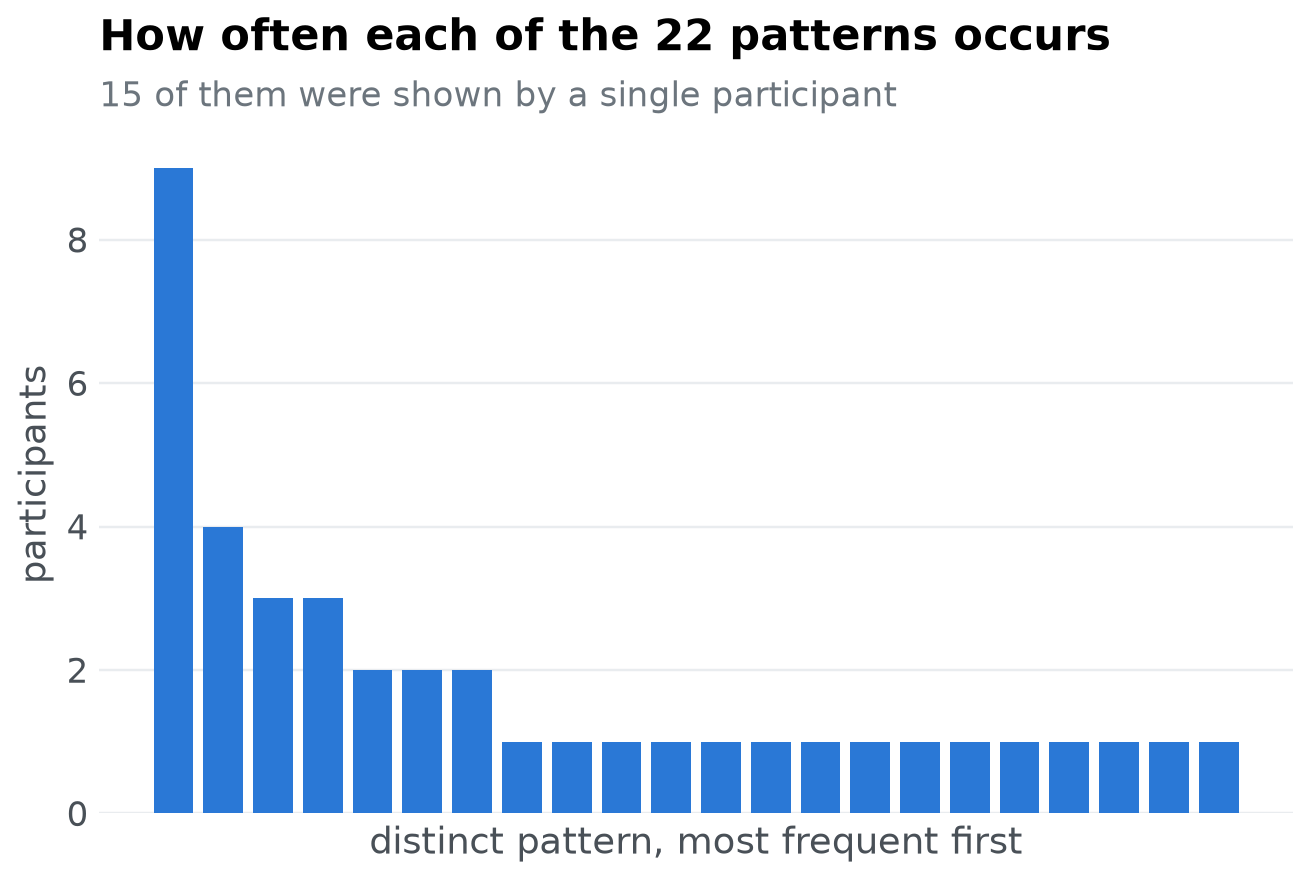

In [7]:
order = torch.argsort(people.counts, descending=True, stable=True)
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(np.arange(people.n), people.counts[order], color=blue, width=0.8)
ax.set(xticks=[], xlabel="distinct pattern, most frequent first", ylabel="participants")
ax.yaxis.get_major_locator().set_params(integer=True)
titled(ax, f"How often each of the {people.n} patterns occurs",
       f"{int((people.counts == 1).sum())} of them were shown by a single participant")
show(fig, "pattern-frequencies")

## Step 2: what could anyone have done?

To judge whether a model is too flexible, we need to know how many patterns were possible at all: the **universal set**. With four stimuli and "about the same" meaning "within the threshold", the patterns are what mathematicians call *semiorders*, and there are exactly

In [8]:
clobe.semiorders(4)

183

of them. Because our measurements are proportions of 20 trials, we can also check that this measurement scale can produce every one of them:

In [9]:
clobe.brutes(torch.arange(21, dtype=torch.float64) / 20, 4, thresholds, return_matrices=False).n

183

It can, so the universal set has `semiorders(4)` patterns.

## Step 3: what can the model do?

A model is a set of patterns too: the patterns it produces across its parameter space. Here are two toy models of the response probabilities, both built on the same feature $x$ of the stimuli ($-1.5, -0.5, 0.5, 1.5$) and the logistic function $\sigma(z) = 1 / (1 + e^{-z})$, which turns any number into a probability:

- The **linear** model, $p_i = \sigma(b \, x_i)$, has one parameter, the slope $b$. A positive slope makes responses rise from stimulus 0 to stimulus 3, a negative one makes them fall, and a slope near 0 makes them all about the same. Whatever $b$ is, the responses change in one direction only: the model can produce monotonic patterns and nothing else. It is the process that generated the participants above, without their noise.
- The **quadratic** model, $p_i = \sigma(b \, x_i + c \, x_i^2)$, adds a curvature $c$. A positive $c$ bends the responses into a U (the middle stimuli lowest), a negative $c$ into an inverted U. With $c = 0$ it is the linear model, so it can produce everything the linear model can, and more.

Each model is evaluated on a grid of parameter values from $-3$ to $3$ in steps of $0.1$: 61 slopes for the linear model, $61 \times 61$ pairs for the quadratic. Both are written for a whole batch of parameter sets at once, as `psp` models are.

In [10]:
def linear(b):
    return torch.sigmoid(b[:, None] * x)


def quadratic(theta):
    return torch.sigmoid(theta[:, :1] * x + theta[:, 1:] * x**2)


grid = torch.arange(-30, 31, dtype=torch.float64) / 10
b, c = torch.meshgrid(grid, grid, indexing="ij")
models = {
    "linear": clobe.patterns(linear(grid), thresholds),
    "quadratic": clobe.patterns(quadratic(torch.stack([b.reshape(-1), c.reshape(-1)], 1)), thresholds),
}
{name: model.n for name, model in models.items()}

{'linear': 7, 'quadratic': 73}

Where in its parameter space does the quadratic model do what people do? Evaluated on a fine grid, each point of the map below is coloured by whether its pattern is one that some participant showed; white lines separate the regions of different patterns. The linear model is the line $c = 0$.

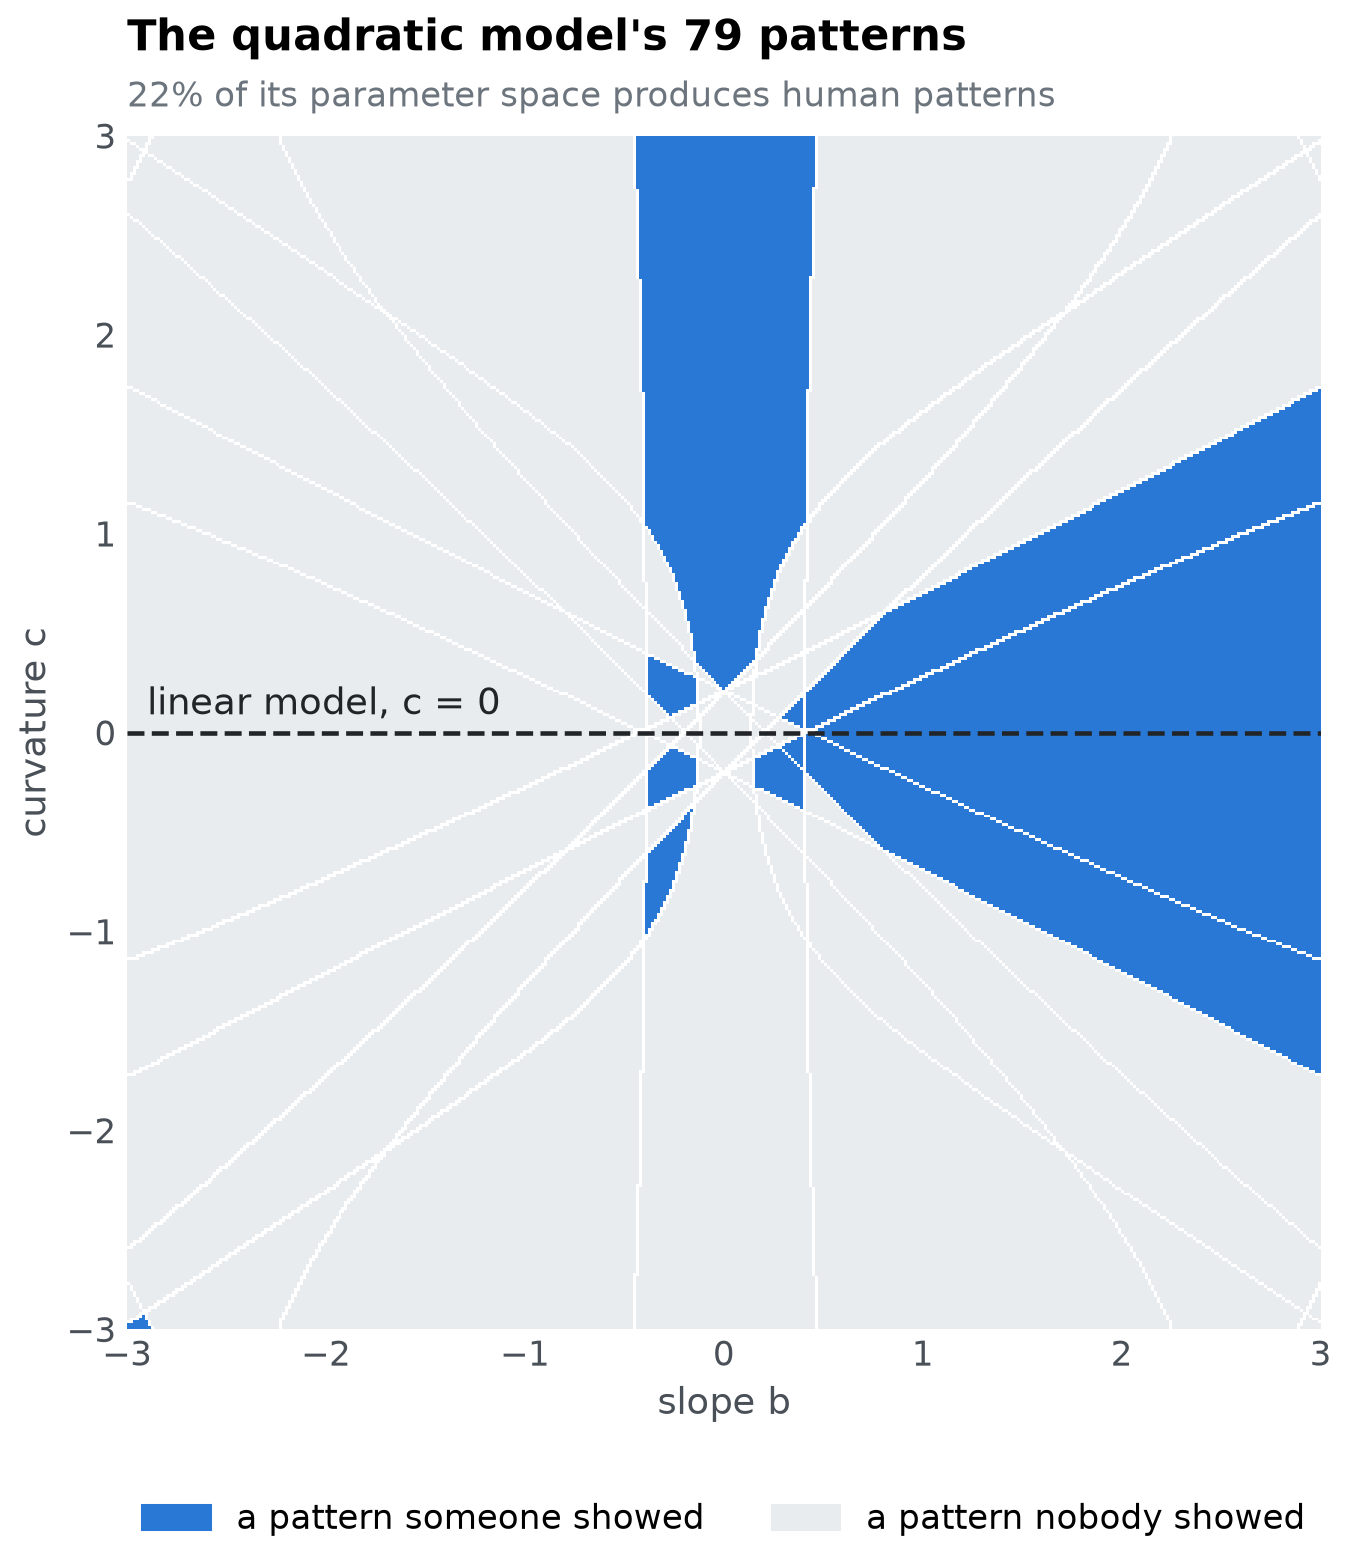

In [11]:
fine = torch.linspace(-3, 3, 401, dtype=torch.float64)
B, C = torch.meshgrid(fine, fine, indexing="ij")
on_map = clobe.patterns(quadratic(torch.stack([B.reshape(-1), C.reshape(-1)], 1)), thresholds)
shown = keys(people.inequality_matrices)
human_like = torch.tensor([r in shown for r in rows(on_map.inequality_matrices)])
region = on_map.pattern.reshape(401, 401).T  # rows: curvature c, columns: slope b
edge = torch.zeros_like(region, dtype=torch.bool)
edge[1:] |= region[1:] != region[:-1]
edge[:, 1:] |= region[:, 1:] != region[:, :-1]
image = np.empty((401, 401, 3))
image[...] = matplotlib.colors.to_rgb(light)
image[human_like[region].numpy()] = matplotlib.colors.to_rgb(blue)
image[edge.numpy()] = (1, 1, 1)

fig, ax = plt.subplots(figsize=(7, 7.6))
ax.imshow(image, origin="lower", extent=(-3, 3, -3, 3), interpolation="nearest")
ax.axhline(0, color=ink, linestyle="--", linewidth=1.5)
ax.annotate("linear model, c = 0", (-2.9, 0), xytext=(0, 6), textcoords="offset points", color=ink)
ax.grid(False)
ax.set(xlabel="slope b", ylabel="curvature c")
ax.legend(handles=[matplotlib.patches.Patch(color=blue, label="a pattern someone showed"),
                   matplotlib.patches.Patch(color=light, label="a pattern nobody showed")],
          loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=2)
titled(ax, f"The quadratic model's {on_map.n} patterns",
       f"{float(human_like[on_map.pattern].double().mean()):.0%} of its parameter space produces human patterns")
show(fig, "quadratic-parameter-space")

## Step 4: compare

`gdistance()` takes the human patterns, the model patterns, the size of the universal set, a weight, and how often each human pattern occurred.

In [12]:
def compare(model):
    out = clobe.gdistance(people.inequality_matrices, model.inequality_matrices,
                          universal=clobe.semiorders(4), weight=0.5,
                          frequencies=people.frequencies)
    return {"alpha": out.alpha, "beta": out.beta, "g": out.gdistance}


results = pd.DataFrame({name: compare(model) for name, model in models.items()}).T
results.round(3)

,alpha,beta,g
linear,0.225,0.037,0.549
quadratic,0.575,0.385,0.406


- **alpha** is the proportion of participants whose pattern the model can produce. Higher is better.
- **beta** is the proportion of the patterns *nobody showed* that the model produces anyway. Lower is better.
- **g** is the distance from the ideal model, which produces every observed pattern and nothing else. Lower is better; it runs from 0 to 1.

In [13]:
r = results.round(3)
display(Markdown(
    f"The quadratic model accommodates {'more' if r.alpha.quadratic > r.alpha.linear else 'no more'} participants "
    f"({r.alpha.quadratic} against {r.alpha.linear}), and produces patterns that nobody produced "
    f"(beta of {r.beta.quadratic} against {r.beta.linear}). g-distance weighs the two; with `weight=0.5` they "
    f"count equally, and here the {r.g.idxmin()} model ends up closer to the ideal. "
    "[gdistance.ipynb](gdistance.ipynb) explains the formula and how to choose the weight."
))

The quadratic model accommodates more participants (0.575 against 0.225), and produces patterns that nobody produced (beta of 0.385 against 0.037). g-distance weighs the two; with `weight=0.5` they count equally, and here the quadratic model ends up closer to the ideal. [gdistance.ipynb](gdistance.ipynb) explains the formula and how to choose the weight.

## Step 3 again, with parameter space partitioning

A grid is fine for two parameters, but it is not how one finds the patterns of a model with many: that is the job of `psp.PSP`, which searches the parameter space for every pattern the model can produce. `clobe.imac` works on a whole batch of results, so it is the `discretize` of the run as it is, and the patterns the run finds go straight into `gdistance()`.

In [14]:
from functools import partial

from psp import PSP

run = PSP(
    quadratic,
    partial(clobe.imac, thresholds=thresholds),
    {"lower": [-3, -3], "upper": [3, 3], "init": [[0.0, 0.0]], "radius": 0.5,
     "population": 200, "iterations": 300},
    generator=torch.Generator().manual_seed(1),
    quiet=True,
)
found = clobe.gdistance(people.inequality_matrices, run.ordinal_patterns,
                        universal=clobe.semiorders(4), weight=0.5, frequencies=people.frequencies)

by_search, by_grid = keys(run.ordinal_patterns), keys(models["quadratic"].inequality_matrices)
grid_g = results.g.quadratic
display(Markdown(
    f"The search finds {len(by_search)} patterns and the grid {len(by_grid)}: {len(by_search & by_grid)} "
    f"are found by both, {len(by_search - by_grid)} only by the search and {len(by_grid - by_search)} only "
    "by the grid. Neither is complete: a region of the parameter space that lies between the points of "
    "the grid is invisible to the grid, however fine it looks, and the search stops after 300 iterations, "
    f"before it has reached every region. With its patterns, the quadratic model has α = {found.alpha:.3f}, β = {found.beta:.3f} and "
    f"g = {found.gdistance:.3f}, against g = {grid_g:.3f} from the grid: the model is judged on the "
    "patterns it can produce, so how they are found matters."
))

The search finds 76 patterns and the grid 73: 70 are found by both, 6 only by the search and 3 only by the grid. Neither is complete: a region of the parameter space that lies between the points of the grid is invisible to the grid, however fine it looks, and the search stops after 300 iterations, before it has reached every region. With its patterns, the quadratic model has α = 0.700, β = 0.391 and g = 0.349, against g = 0.406 from the grid: the model is judged on the patterns it can produce, so how they are found matters.

## Reference

Dome, L., & Wills, A. J. (2025). g-Distance: On the comparison of model and human heterogeneity. *Psychological Review, 132*(3), 632-655. https://doi.org/10.1037/rev0000550